## **Business Understanding**

 



- Africa experiences frequent natural and human-related disasters, including floods, epidemics, droughts and storms. These events cause heavy loss of life and strain the resources of governments and humanitarian organizations. Disaster response agencies often lack early, data-driven estimates of how deadly an event is likely to be, which makes it hard to prioritize aid, medical supplies and emergency personnel.

- This notebook analyzes historical disaster records (EM-DAT) across African countries to understand the patterns behind disaster-related deaths. It then builds machine learning models that predict Estimated Deaths, so that decision-makers can allocate resources more effectively and prepare for high-risk events.

Objective:To analyze historical disaster data in Africa and develop predictive models that estimate the number of deaths caused by disaster events

 <a  href="https://doc.emdat.be/docs/data-structure-and-content/emdat-public-table/">Source 1</a> 


 <a href="https://doc.emdat.be/docs/data-structure-and-content/emdat-public-table/">Source 2</a>

#### **Loading libraries**

In [270]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import xgboost as xgb
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold

#### **Load data**

In [212]:
df = pd.read_excel("C:\\Users\\USER\\Documents\\Final project\\emdat_with_estimated_deaths.xlsx")

In [213]:
df.head(2)

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-03-09,2026-05-15
1,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15


## **Data Understanding**

In [214]:
df.head(5)

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-03-09,2026-05-15
1,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15
2,2025-9122-SOM,No,nat-cli-dro-dro,Natural,Climatological,Drought,Drought,NaN,NaN,SOM,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-02-26,2026-05-15
3,2026-0310-COD,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,COD,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-05-05,2026-05-20
4,2025-0694-SOM,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000142,Diphteria,SOM,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-08-20,2026-06-10


In [215]:
df.dtypes

DisNo.                                           str
Historic                                         str
Classification Key                               str
Disaster Group                                   str
Disaster Subgroup                                str
Disaster Type                                    str
Disaster Subtype                                 str
External IDs                                     str
Event Name                                       str
ISO                                              str
Country                                          str
Subregion                                        str
Region                                           str
Location                                         str
Origin                                           str
Associated Types                                 str
OFDA/BHA Response                                str
Appeal                                           str
Declaration                                   

In [216]:
df.shape

(2279, 50)

In [217]:
df.isna().sum()

DisNo.                                          0
Historic                                        0
Classification Key                              0
Disaster Group                                  0
Disaster Subgroup                               0
Disaster Type                                   0
Disaster Subtype                                0
External IDs                                 1443
Event Name                                   1586
ISO                                             0
Country                                         0
Subregion                                       0
Region                                          0
Location                                      103
Origin                                       1287
Associated Types                             1768
OFDA/BHA Response                               0
Appeal                                          0
Declaration                                     0
AID Contribution ('000 US$)                  2184


#### **reasons for a lot of missing values**
- Event details: Columns such as Event Name, External IDs, and Origin contain missing values because some events have no recorded name, external reference, or documented cause
- Geographical information: Latitude, Longitude, and River Basin have missing values because precise coordinates or river basin information may not be available or relevant to every disaster.
- Casualties and impact: Columns such as Total Deaths, No. Injured, No. Homeless, and No. Affected have missing values because these figures may not have been reported or verified
- Financial information: Columns such as AID Contribution, Reconstruction Costs, and Insured Damage have missing values because financial losses, insurance claims, or aid contributions may not have been assessed or documented
- Dates and magnitude: Missing values in Start Day, End Day, Magnitude, and Magnitude Scale may occur when the exact dates or measurements of a disaster are unknown or unavailable
- Administrative information: Missing values in Admin Units and GADM Admin Units may result from incomplete geographical or administrative records

#### **Data cleaning**

In [218]:
columns_to_drop = [
    'DisNo.',
    'External IDs',
    'Event Name',
    'Entry Date',
    'Last Update',
    'Classification Key',
    'Disaster Group',
    'Disaster Subgroup',
    'Disaster Subtype',
    'Origin',
    'Associated Types',
    "AID Contribution ('000 US$)",
    'Magnitude',
    'Latitude',
    'Longitude',
    'River Basin',
    'No. Injured',
    'No. Homeless',
    "Reconstruction Costs ('000 US$)",
    "Reconstruction Costs, Adjusted ('000 US$)",
    "Insured Damage ('000 US$)",
    "Insured Damage, Adjusted ('000 US$)",
    "Total Damage ('000 US$)",
    "Total Damage, Adjusted ('000 US$)",
    "DisNo.",
    
    "End Day",
    "End Month",
    "Deaths Is Estimated",
    "Deaths Estimate Method",
    "Total Deaths",
    "Magnitude Scale",
    "GADM Admin Units",
    "Admin Units"
    
]

In [219]:
df_2=df.drop(columns=columns_to_drop)
print(f"Original columns: {df.shape[1]}")
print(f"Cleaned columns:  {df_2.shape[1]}")

Original columns: 50
Cleaned columns:  18


In [220]:
df_2.isnull().sum()

Historic               0
Disaster Type          0
ISO                    0
Country                0
Subregion              0
Region                 0
Location             103
OFDA/BHA Response      0
Appeal                 0
Declaration            0
Start Year             0
Start Month           50
Start Day            630
End Year               0
Estimated Deaths       0
No. Affected         600
Total Affected       194
CPI                   35
dtype: int64

In [221]:
df_2.head(5)

,Historic,Disaster Type,ISO,Country,Subregion,Region,Location,OFDA/BHA Response,Appeal,Declaration,Start Year,Start Month,Start Day,End Year,Estimated Deaths,No. Affected,Total Affected,CPI
0,No,Flood,KEN,Kenya,Sub-Saharan Africa,Africa,"Mombasa, Kwale, Kilifi, Tana River, Lamu, Tait...",No,No,No,2026,3.0,6.0,2026,59,NaN,27.0,NaN
1,No,Epidemic,AGO,Angola,Sub-Saharan Africa,Africa,Cacuaco (Luanda province); Bengo; Icolo e Beng...,No,No,No,2025,1.0,7.0,2025,776,NaN,27728.0,100.0
2,No,Drought,SOM,Somalia,Sub-Saharan Africa,Africa,"Gedo, Hiran, Bay, Bakool, Mudug, Bari, Toghdhe...",No,No,Yes,2025,1.0,NaN,2026,58,6500000.0,6500000.0,100.0
3,No,Flood,COD,Democratic Republic of the Congo,Sub-Saharan Africa,Africa,"Maniema, Uvira (South Kivu province)",No,No,No,2026,5.0,1.0,2026,6,79000.0,79000.0,NaN
4,No,Epidemic,SOM,Somalia,Sub-Saharan Africa,Africa,Daynile and Harmaweyne (Banadir); Galkayo and ...,No,No,No,2025,NaN,NaN,2026,89,NaN,1811.0,100.0


In [222]:
df_2.columns

Index(['Historic', 'Disaster Type', 'ISO', 'Country', 'Subregion', 'Region',
       'Location', 'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'Estimated Deaths',
       'No. Affected', 'Total Affected', 'CPI'],
      dtype='str')

#### **Univariate Analysis**

In [223]:
df_2["Disaster Type"].value_counts()

Disaster Type
Flood                  1030
Epidemic                616
Storm                   261
Drought                 179
Mass movement (wet)      74
Earthquake               34
Wildfire                 33
Infestation              22
Extreme temperature      17
Volcanic activity        10
Mass movement (dry)       2
Animal incident           1
Name: count, dtype: int64

In [224]:
disaster_counts = df_2["Disaster Type"].value_counts()

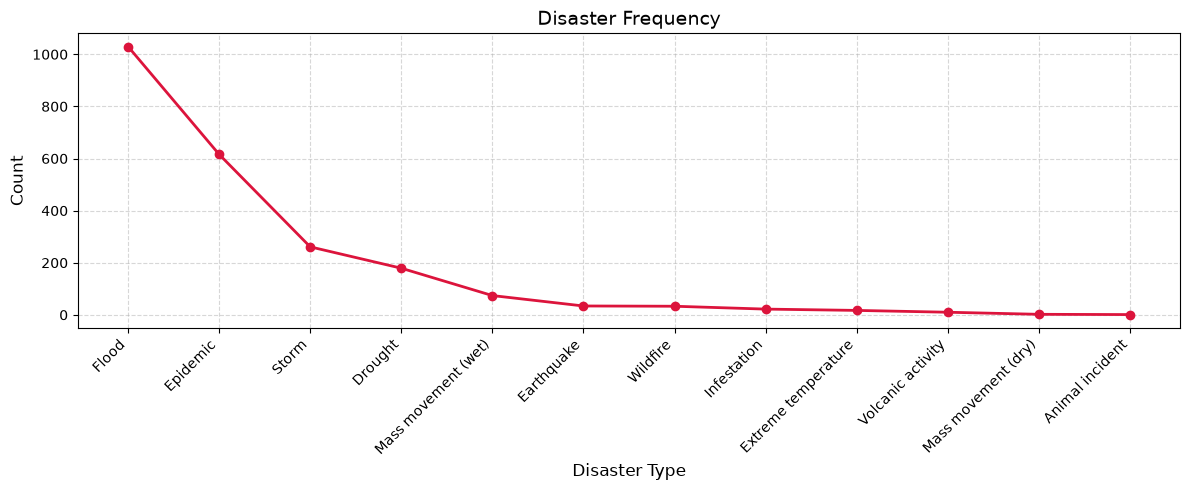

In [273]:
plt.figure(figsize=(12, 5))
plt.plot(disaster_counts.index, disaster_counts.values, marker='o', color='crimson', linewidth=2)

plt.title('Disaster Frequency', fontsize=14)
plt.xlabel('Disaster Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##### **Insights on disaster types**
The  analysis of disaster types shows that floods are the most frequently recorded disasters, with 1,030 cases, followed by epidemics with 616 cases and storms with 261 cases. Droughts account for 179 cases, while wet mass movements account for 74 cases. Earthquakes and wildfires have 34 and 33 cases, respectively. Infestations, extreme temperatures, volcanic activity, dry mass movements, and animal incidents are less common, with 22, 17, 10, 2, and 1 cases, respectively.
- Understanding their frequency can help identify disaster patterns and inform disaster preparedness and resource allocation.

#### **Bivariate Analysis**

In [226]:
df_2.columns

Index(['Historic', 'Disaster Type', 'ISO', 'Country', 'Subregion', 'Region',
       'Location', 'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'Estimated Deaths',
       'No. Affected', 'Total Affected', 'CPI'],
      dtype='str')

In [227]:

disaster_deaths = df_2.groupby("Disaster Type")["Estimated Deaths"].sum().reset_index()
disaster_deaths = disaster_deaths.sort_values(by="Estimated Deaths", ascending=True)
print(disaster_deaths)

          Disaster Type  Estimated Deaths
0       Animal incident                12
7   Mass movement (dry)               114
10    Volcanic activity               264
6           Infestation               352
4   Extreme temperature               416
11             Wildfire               604
8   Mass movement (wet)              4235
2            Earthquake              7593
9                 Storm             20606
1               Drought             31204
5                 Flood             31944
3              Epidemic            102580


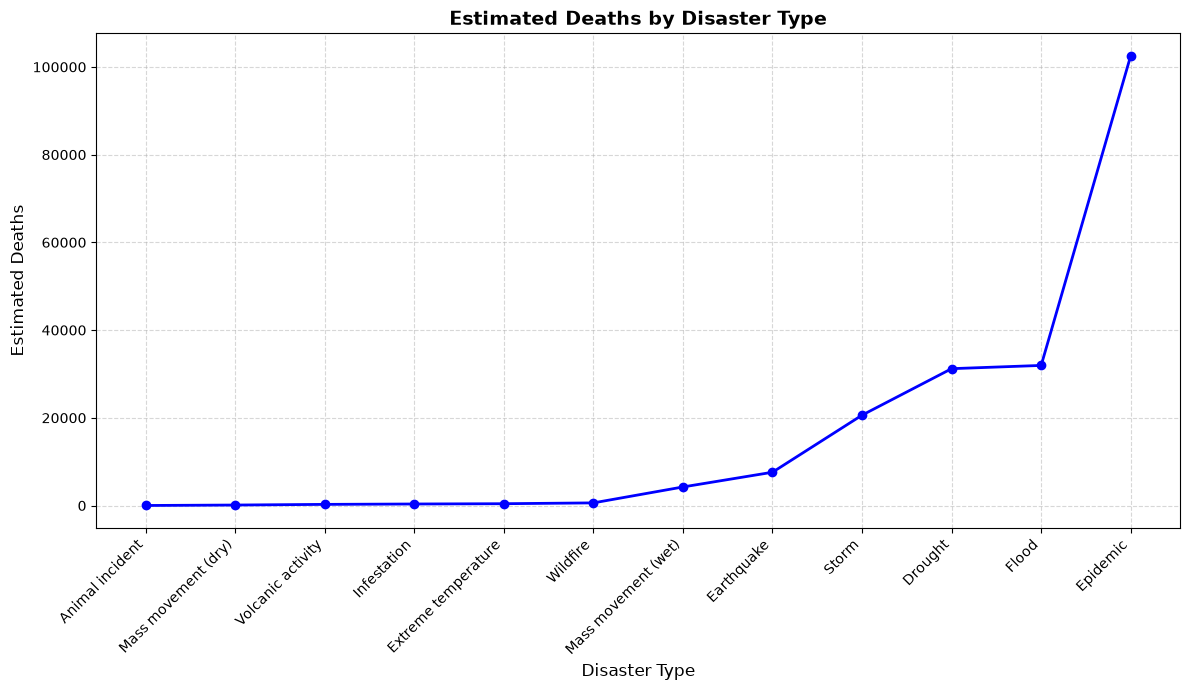

In [274]:
plt.figure(figsize=(12, 7))
plt.plot(
    disaster_deaths["Disaster Type"],
    disaster_deaths["Estimated Deaths"],
    marker="o",
    linewidth=2,
    color="blue",
)
plt.title("Estimated Deaths by Disaster Type", fontsize=14, fontweight="bold")
plt.xlabel("Disaster Type", fontsize=12)
plt.ylabel("Estimated Deaths", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

##### **Insights**
- Epidemics account for the highest total estimated fatalities with 102,580 deaths. 
- Floods (31,944 deaths) and Droughts (31,204 deaths) represent the second and third most fatal categories
- Storms (20,606 deaths) and Earthquakes (7,593 deaths) form the secondary cluster of high-fatality disaster types

#### **Multivariate Analysis**

In [275]:
grouped_deaths = df.groupby(['Disaster Type', 'Country','End Year','Start Year'])['Estimated Deaths'].sum().reset_index()
print(grouped_deaths.sort_values( by='Estimated Deaths',ascending=False).head(15))


     Disaster Type                           Country  End Year  Start Year  \
140        Drought                           Somalia      2011        2010   
1503         Storm                             Libya      2023        2023   
415       Epidemic                           Liberia      2016        2014   
636       Epidemic                          Zimbabwe      2009        2008   
334       Epidemic  Democratic Republic of the Congo      2019        2019   
533       Epidemic                      Sierra Leone      2015        2014   
302       Epidemic                             Congo      2019        2019   
507       Epidemic                           Nigeria      2021        2021   
195     Earthquake                           Morocco      2023        2023   
849          Flood  Democratic Republic of the Congo      2023        2023   
388       Epidemic                            Guinea      2015        2014   
163        Drought                            Uganda      2022  

In [230]:
top15_deaths = grouped_deaths.sort_values(by='Estimated Deaths', ascending=False).head(15)

In [231]:
heatmap_matrix = top15_deaths.pivot_table(
    index='Disaster Type',
    columns='Country',
    values='Estimated Deaths',
    aggfunc='sum'  
)

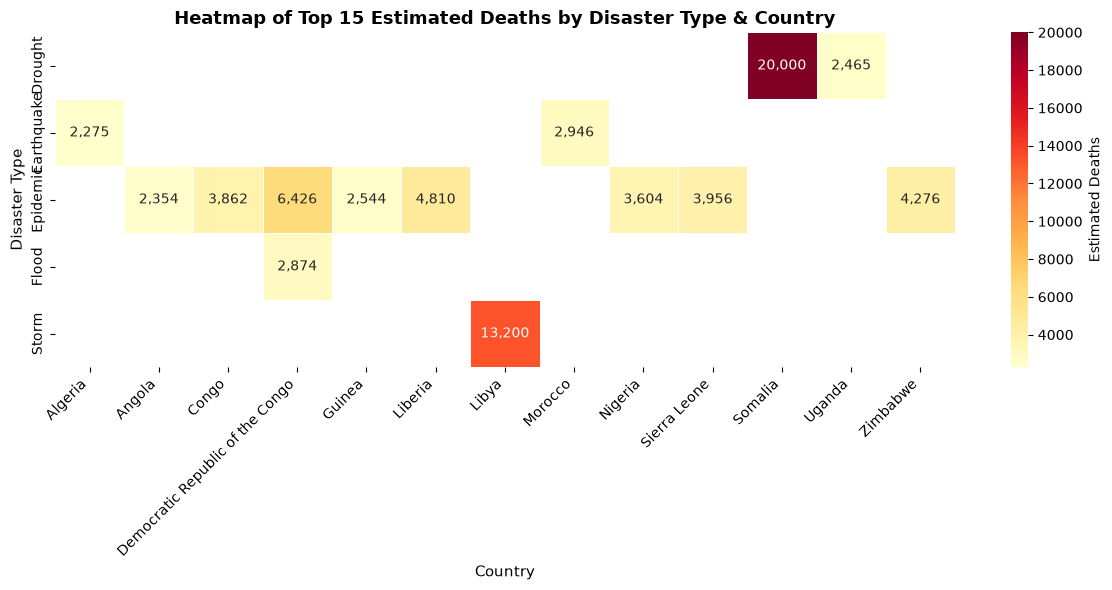

In [232]:
plt.figure(figsize=(12, 6))
sns.heatmap(
    heatmap_matrix, 
    annot=True, 
    fmt=',.0f', 
    cmap='YlOrRd', 
    linewidths=0.5,
    cbar_kws={'label': 'Estimated Deaths'}
)

plt.title('Heatmap of Top 15 Estimated Deaths by Disaster Type & Country', fontsize=13, fontweight='bold')
plt.xlabel('Country', fontsize=11)
plt.ylabel('Disaster Type', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### **Insights**
- Most Severe Single Event: Somalia experienced the single highest loss of life, with 20,000 deaths resulting from the 2010–2011 Drought
- Recent High-Impact Events (2023): Libya suffered severe casualties from a 2023 Storm (13,200 deaths), while DR Congo experienced major Flooding in 2023 (2,874 deaths) alongside its earlier 2018–2019 Epidemics (6,426 combined deaths).
- Widespread Health Crises: The 2014–2016 West African Ebola outbreak accounts for major epidemic fatalities across Liberia (2014–2016), Sierra Leone (2014–2015), and Guinea (2014–2015)

#### **Multi-variate analysis 2(Kenya)**

In [276]:
kenya_df = df[df["ISO"] == "KEN"].copy()
kenya_df = kenya_df.dropna(
    subset=["Start Year", "Disaster Type", "Estimated Deaths"]
)
kenya_analysis = (
    kenya_df.groupby(["Start Year", "Disaster Type"])["Estimated Deaths"]
    .sum()
    .reset_index()
)


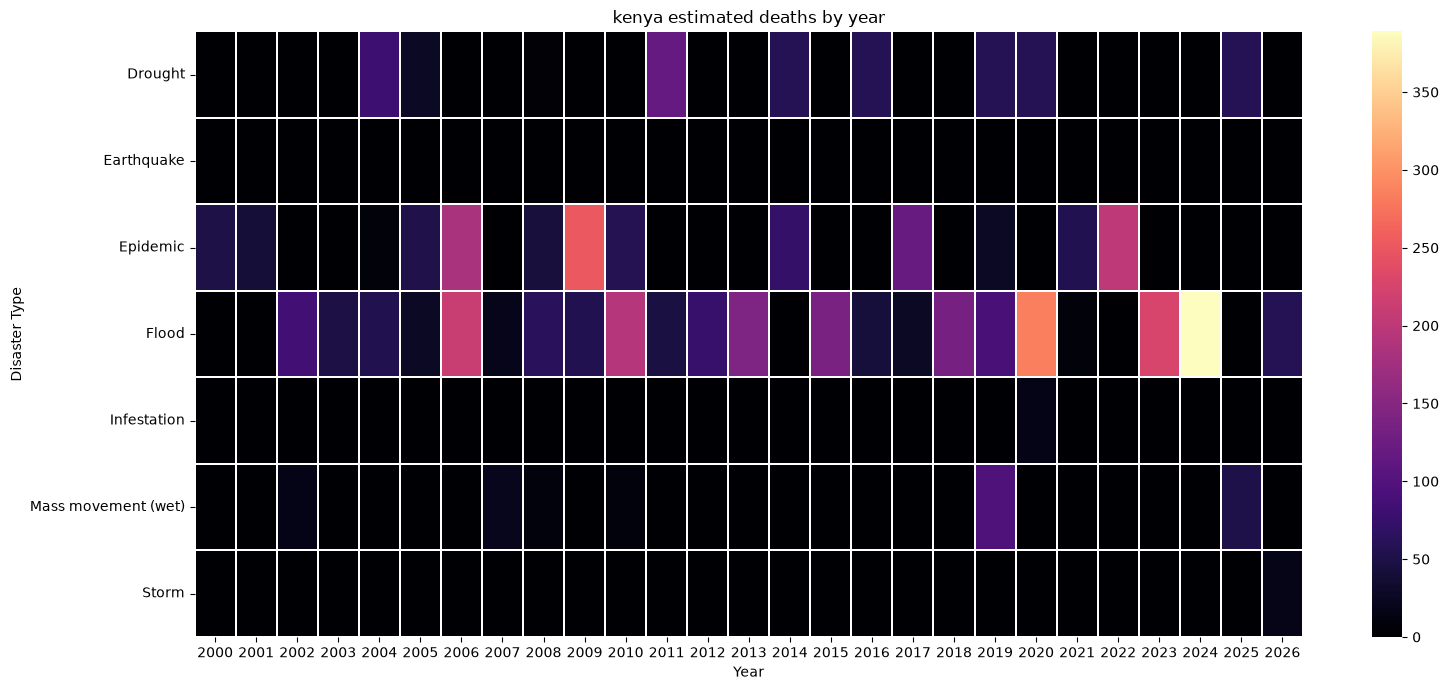

In [277]:
heatmap_data = kenya_analysis.pivot(
    index="Disaster Type",
    columns="Start Year",
    values="Estimated Deaths"
).fillna(0)

plt.figure(figsize=(16, 7))
sns.heatmap(heatmap_data, cmap="magma", linewidths=0.3,linecolor="white",annot=False,)

plt.title("kenya estimated deaths by year")
plt.xlabel("Year")
plt.ylabel("Disaster Type")
plt.tight_layout()
plt.show()

##### *Insights on Kenya*


<u>FLOODS</u>
- Floods are the deadliest and most persistent threat:Floods consistently cause the highest number of deaths across the timeline. The worst single event occurred in 2024, which shows a massive spike in estimated deaths (nearly 400). Other highly fatal flood years include 2020, 2006, and 2023.<br>
<u>EPIDEMICS</u>

- Epidemics are the second major cause of casualties: Epidemics strike less frequently than floods but can be highly deadly, with a major peak around 2009 and significant impacts in 2006, 2017, and 2022
<u>DROUGHTS</u>

- Droughts cause moderate but recurring fatalities: Droughts appear periodically (e.g., 2004, 2011, 2017) but generally result in lower direct death tolls compared to floods and epidemics.  
<u>OTHERS</u> 
4. Other disasters cause minimal direct deaths: Earthquakes, infestations, and storms resulted in nearly zero estimated deaths throughout this 26-year period. Mass movements (wet) only show one notable, moderate peak around 2019.

## **Data preparation**

In [235]:
df_2.head(3)

,Historic,Disaster Type,ISO,Country,Subregion,Region,Location,OFDA/BHA Response,Appeal,Declaration,Start Year,Start Month,Start Day,End Year,Estimated Deaths,No. Affected,Total Affected,CPI
0,No,Flood,KEN,Kenya,Sub-Saharan Africa,Africa,"Mombasa, Kwale, Kilifi, Tana River, Lamu, Tait...",No,No,No,2026,3.0,6.0,2026,59,NaN,27.0,NaN
1,No,Epidemic,AGO,Angola,Sub-Saharan Africa,Africa,Cacuaco (Luanda province); Bengo; Icolo e Beng...,No,No,No,2025,1.0,7.0,2025,776,NaN,27728.0,100.0
2,No,Drought,SOM,Somalia,Sub-Saharan Africa,Africa,"Gedo, Hiran, Bay, Bakool, Mudug, Bari, Toghdhe...",No,No,Yes,2025,1.0,NaN,2026,58,6500000.0,6500000.0,100.0


In [236]:
df_3 = pd.get_dummies(df_2, columns=["Disaster Type"], prefix="Disaster", dtype=int)

In [237]:
df_3.columns

Index(['Historic', 'ISO', 'Country', 'Subregion', 'Region', 'Location',
       'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'Estimated Deaths',
       'No. Affected', 'Total Affected', 'CPI', 'Disaster_Animal incident',
       'Disaster_Drought', 'Disaster_Earthquake', 'Disaster_Epidemic',
       'Disaster_Extreme temperature', 'Disaster_Flood',
       'Disaster_Infestation', 'Disaster_Mass movement (dry)',
       'Disaster_Mass movement (wet)', 'Disaster_Storm',
       'Disaster_Volcanic activity', 'Disaster_Wildfire'],
      dtype='str')

In [238]:
pd.DataFrame.describe(df_3)

,Start Year,Start Month,Start Day,End Year,Estimated Deaths,No. Affected,Total Affected,CPI,Disaster_Animal incident,Disaster_Drought,Disaster_Earthquake,Disaster_Epidemic,Disaster_Extreme temperature,Disaster_Flood,Disaster_Infestation,Disaster_Mass movement (dry),Disaster_Mass movement (wet),Disaster_Storm,Disaster_Volcanic activity,Disaster_Wildfire
count,2279.000000,2229.000000,1649.000000,2279.000000,2279.000000,1.679000e+03,2.085000e+03,2244.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000
mean,2011.808688,5.980260,14.067920,2011.943835,87.724441,3.574611e+05,2.905224e+05,71.202266,0.000439,0.078543,0.014919,0.270294,0.007459,0.451953,0.009653,0.000878,0.032470,0.114524,0.004388,0.014480
std,7.872965,3.627341,9.187053,7.891795,576.110234,1.492437e+06,1.346474e+06,13.089860,0.020947,0.269084,0.121255,0.444209,0.086064,0.497795,0.097798,0.029617,0.177285,0.318516,0.066110,0.119485
min,2000.000000,1.000000,1.000000,2000.000000,1.000000,1.000000e+00,1.000000e+00,53.487737,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2005.000000,3.000000,6.000000,2005.000000,8.000000,1.000000e+03,7.500000e+02,60.660332,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2011.000000,6.000000,14.000000,2011.000000,15.000000,9.935000e+03,5.733000e+03,67.731095,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2019.000000,9.000000,22.000000,2019.000000,44.000000,8.481200e+04,5.025400e+04,79.410785,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,2026.000000,12.000000,31.000000,2026.000000,20000.000000,2.597281e+07,2.597281e+07,100.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [239]:
columns_to_encode = ['Historic', 'Appeal', 'Declaration']

for col in columns_to_encode:  df_3[col] = df_3[col].map({'Yes': 1, 'No': 0})

In [240]:
df_3.head(3)

,Historic,ISO,Country,Subregion,Region,Location,OFDA/BHA Response,Appeal,Declaration,Start Year,...,Disaster_Earthquake,Disaster_Epidemic,Disaster_Extreme temperature,Disaster_Flood,Disaster_Infestation,Disaster_Mass movement (dry),Disaster_Mass movement (wet),Disaster_Storm,Disaster_Volcanic activity,Disaster_Wildfire
0,0,KEN,Kenya,Sub-Saharan Africa,Africa,"Mombasa, Kwale, Kilifi, Tana River, Lamu, Tait...",No,0,0,2026,...,0,0,0,1,0,0,0,0,0,0
1,0,AGO,Angola,Sub-Saharan Africa,Africa,Cacuaco (Luanda province); Bengo; Icolo e Beng...,No,0,0,2025,...,0,1,0,0,0,0,0,0,0,0
2,0,SOM,Somalia,Sub-Saharan Africa,Africa,"Gedo, Hiran, Bay, Bakool, Mudug, Bari, Toghdhe...",No,0,1,2025,...,0,0,0,0,0,0,0,0,0,0


In [241]:
df_4.columns

Index(['Historic', 'Country', 'OFDA/BHA Response', 'Appeal', 'Declaration',
       'Start Year', 'Start Month', 'Start Day', 'End Year',
       'Estimated Deaths', 'No. Affected', 'Total Affected', 'CPI',
       'Disaster_Animal incident', 'Disaster_Drought', 'Disaster_Earthquake',
       'Disaster_Epidemic', 'Disaster_Extreme temperature', 'Disaster_Flood',
       'Disaster_Infestation', 'Disaster_Mass movement (dry)',
       'Disaster_Mass movement (wet)', 'Disaster_Storm',
       'Disaster_Volcanic activity', 'Disaster_Wildfire'],
      dtype='str')

In [242]:
df_4 = df_3.drop(columns=["ISO", "Region", "Location",]).copy()

In [243]:
df_4["OFDA/BHA Response"] = df_4["OFDA/BHA Response"].map({"Yes": 1, "No": 0})

In [244]:
df_4 = pd.get_dummies(df_4, columns=["Country", "Subregion"], dtype=int)

In [245]:
missing_cols = df_4.isnull().sum()[df_4.isnull().sum() > 0]
print(missing_cols)

Start Month        50
Start Day         630
No. Affected      600
Total Affected    194
CPI                35
dtype: int64


In [246]:
df_4.head(3)

,Historic,OFDA/BHA Response,Appeal,Declaration,Start Year,Start Month,Start Day,End Year,Estimated Deaths,No. Affected,...,Country_South Sudan,Country_Sudan,Country_Togo,Country_Tunisia,Country_Uganda,Country_United Republic of Tanzania,Country_Zambia,Country_Zimbabwe,Subregion_Northern Africa,Subregion_Sub-Saharan Africa
0,0,0,0,0,2026,3.0,6.0,2026,59,NaN,...,0,0,0,0,0,0,0,0,0,1
1,0,0,0,0,2025,1.0,7.0,2025,776,NaN,...,0,0,0,0,0,0,0,0,0,1
2,0,0,0,1,2025,1.0,NaN,2026,58,6500000.0,...,0,0,0,0,0,0,0,0,0,1


## **Modeling**

##### **Classical models**

In [247]:
y = np.log1p(df_4["Estimated Deaths"])
X = df_4.drop(columns=["Estimated Deaths"])

In [248]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [249]:
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

In [250]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

In [251]:

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=15,
                                           min_samples_leaf=2, random_state=42, n_jobs=-1),
    
}


In [ ]:
 
def evaluate(name, y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.clip(np.expm1(y_pred_log), 0, None)
    return {
        "Model": name,
        "R2 (log)": r2_score(y_true_log, y_pred_log),
        "RMSE (log)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE (deaths)": mean_absolute_error(y_true, y_pred),
        "RMSE (deaths)": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

In [253]:
results, preds = [], {}
for name, model in models.items():
    
    if name == "Linear Regression":
        model.fit(X_train_sc, y_train)
        p = model.predict(X_test_sc)
    else:
        model.fit(X_train, y_train)
        p = model.predict(X_test)
    preds[name] = p
    results.append(evaluate(name, y_test, p))
    

In [254]:
joblib.dump(models["Linear Regression"], "linear_regression.joblib")
joblib.dump(models["Decision Tree"], "decision_tree.joblib")
joblib.dump(models["Random Forest"], "random_forest.joblib")

['random_forest.joblib']

In [255]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

In [256]:
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
xgb_results = evaluate("XGBoost", y_test, y_pred_xgb)
print(pd.DataFrame([xgb_results]).round(2))


     Model  R2 (log)  RMSE (log)  MAE (deaths)  RMSE (deaths)
0  XGBoost      0.48        0.97         56.16         245.68


In [257]:
joblib.dump(xgb_model, "xgb.joblib")

['xgb.joblib']

In [272]:
param_grid = {
    "n_estimators":     [300, 500, 800, 1000],
    "learning_rate":    [0.01, 0.03, 0.05, 0.1],
    "max_depth":        [5,6,7,8,9,10],
    "min_child_weight": [1, 2, 3,5 ],
    "subsample":        [0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "reg_alpha":        [0, 0.1, 1],
    "reg_lambda":       [0.5, 1, 2, 5],
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.85, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [5, 6, ...], 'min_child_weight': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a b

In [259]:
best_xgb = search.best_estimator_
y_pred_tuned = best_xgb.predict(X_test)
tuned_results = evaluate("XGBoost (tuned)", y_test, y_pred_tuned)
print(pd.DataFrame([xgb_results, tuned_results]).round(3))

joblib.dump(best_xgb, "xgb_tuned.joblib")

             Model  R2 (log)  RMSE (log)  MAE (deaths)  RMSE (deaths)
0          XGBoost     0.478       0.975        56.165        245.682
1  XGBoost (tuned)     0.473       0.980        57.354        261.400


['xgb_tuned.joblib']

Despite doing hyper parameter tuning on my best model the results came worse than the orginal model so i'll stick with using the originall as my preferred model

## **Evaluation**

MAE-How far off is a typical prediction on average

RMSE - How badly does the model fail on extreme misses

R2 - How much of the problem's underlying pattern did the model learn

In [260]:
results_df = pd.DataFrame(results)
print(results_df)

               Model  R2 (log)  RMSE (log)  MAE (deaths)  RMSE (deaths)
0  Linear Regression  0.301565    1.127967     67.032404     302.016767
1      Decision Tree  0.345175    1.092185     62.087442     274.668885
2      Random Forest  0.437963    1.011849     57.216497     259.250034


In [264]:
print(pd.DataFrame([xgb_results]).round(3))

     Model  R2 (log)  RMSE (log)  MAE (deaths)  RMSE (deaths)
0  XGBoost     0.478       0.975        56.165        245.682


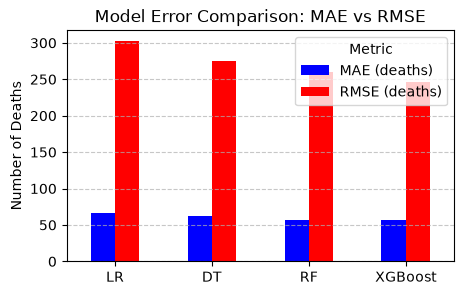

In [267]:
results_data = {
    'Model': ['LR', 'DT', 'RF', 'XGBoost'],
    'MAE (deaths)': [67.0, 62.1, 57.2, 56.2],
    'RMSE (deaths)': [302.0, 274.7, 259.3, 245.68]
}
df_results = pd.DataFrame(results_data).set_index('Model')
ax = df_results.plot(kind='bar', figsize=(5, 3), color=['blue', 'red'])
plt.title('Model Error Comparison: MAE vs RMSE')
plt.ylabel('Number of Deaths')
plt.xlabel('')
plt.xticks(rotation=0)
plt.legend(title='Metric')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

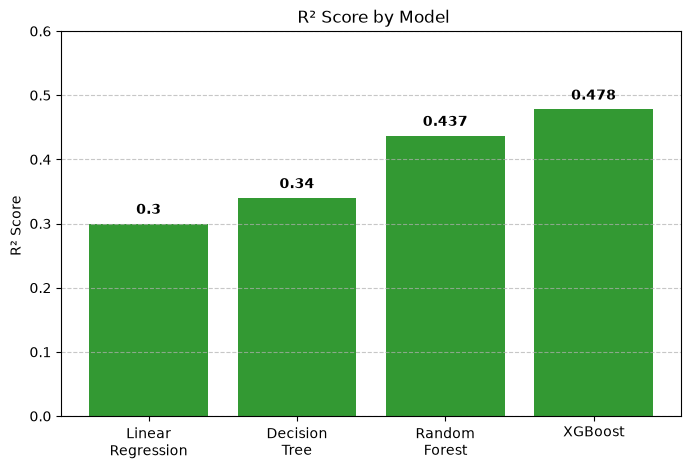

In [269]:
r2_data = {
    'Model': ['Linear\nRegression', 'Decision\nTree', 'Random\nForest', 'XGBoost'],
    'R2 Score': [0.30, 0.34, 0.437, 0.478]
}
df_r2 = pd.DataFrame(r2_data)

plt.figure(figsize=(8, 5))
bars = plt.bar(df_r2['Model'], df_r2['R2 Score'], color='green', alpha=0.8)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, round(yval, 3), 
             ha='center', va='bottom', fontweight='bold')
plt.title(' R² Score by Model')
plt.ylabel('R² Score ')
plt.ylim(0, 0.6) 
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

##### **Insights on the Model perfomace**
**1. Linear Regression**
- It performed the worst, with an R² of 0.302.
- Its average prediction error was approximately 67 deaths.
- This suggests that a simple straight-line relationship may not capture all the patterns in disaster fatalities

**2. Decision Tree**
- It performed slightly better than Linear Regression with an R2 of 0.34
- Its MAE decreased from 67 to approximately 62 deaths.
- This suggests that the relationships in the data may be more complex than Linear Regression can capture

**3. Random Forest**
- It performed much better than both Linear Regression and the single Decision Tree had an r2 score of 0.43
- Its average prediction error was approximately 57 deaths.
- It also had a lower RMSE, suggesting fewer or smaller large prediction errors overall than the earlier models

**4. XGBoost**(Suitable)
- It achieved the highest R² (log), at 0.47
- It had the lowest MAE, at approximately 57 deaths, and the lowest RMSE, at approximately 245 deaths.


#### **Why the models have very low scores**
- Deaths are very skewed. Most events kill few people, and a few kill thousands, and those are very hard to predict from basic columns like type, country and year.
- Missing the strongest drivers. Death counts depend on things like population exposed, warning time, building quality and response speed. A dataset without those can only explain a fraction of the variation.
- Small data. About 2,300 rows isn’t much for a noisy target and alsso part of the reason i didn't implement a deep learning model

## **Deployment**